Available CSV files:
0 kidney_disease.csv
1 kidneyData.csv

Dataset shape: (400, 26)
Columns: ['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd



Target distribution (0=Not CKD, 1=CKD):
_target_
0    150
1    250
Name: count, dtype: int64

Training samples: 320
Testing samples: 80
Numerical columns: ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
Categorical columns: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

Training: Logistic Regression
Accuracy=0.9750, Recall=0.9600, F1=0.9796, ROC-AUC=1.0000

Training: Decision Tree
Accuracy=0.9750, Recall=0.9600, F1=0.9796, ROC-AUC=0.9800

Training: Random Forest
Accuracy=1.0000, Recall=1.0000, F1=1.0000, ROC-AUC=1.0000

Training: Extra Trees
Accuracy=1.0000, Recall=1.0000, F1=1.0000, ROC-AUC=1.0000

Training: SVM
Accuracy=0.9875, Recall=0.9800, F1=0.9899, ROC-AUC=1.0000

Training: Gradient Boosting
Accuracy=1.0000, Recall=1.0000, F1=1.0000, ROC-AUC=1.0000

Training: Voting Ensemble
Accuracy=1.0000, Recall=1.0000, F1=1.0000, ROC-AUC=1.0000

Training: Stacking Ensemble
Accuracy=1.0000, Recall=1.0000, F1=1.0000, ROC-AUC=1

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Extra Trees,1.0000,1.0,1.00,1.0000,1.00
1,Random Forest,1.0000,1.0,1.00,1.0000,1.00
2,Voting Ensemble,1.0000,1.0,1.00,1.0000,1.00
3,Gradient Boosting,1.0000,1.0,1.00,1.0000,1.00
4,Stacking Ensemble,1.0000,1.0,1.00,1.0000,1.00
5,SVM,0.9875,1.0,0.98,0.9899,1.00
6,Logistic Regression,0.9750,1.0,0.96,0.9796,1.00
7,Decision Tree,0.9750,1.0,0.96,0.9796,0.98


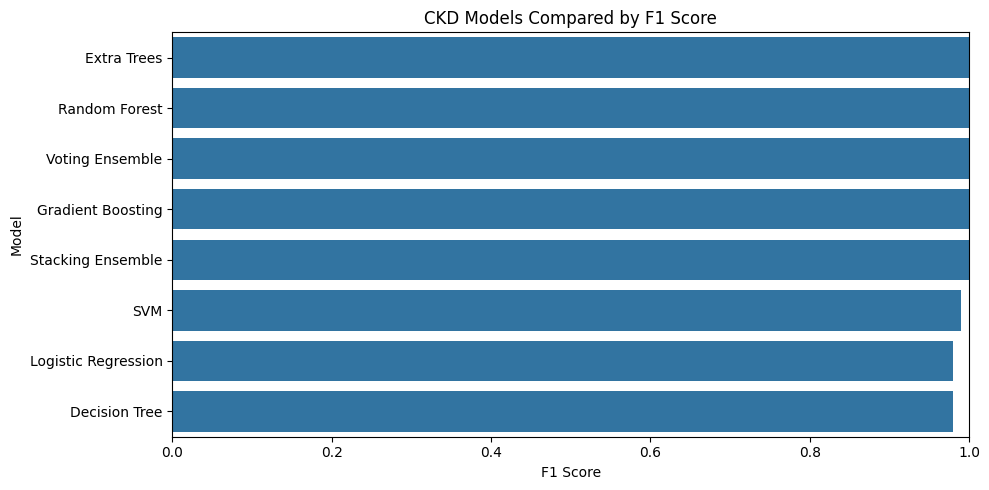

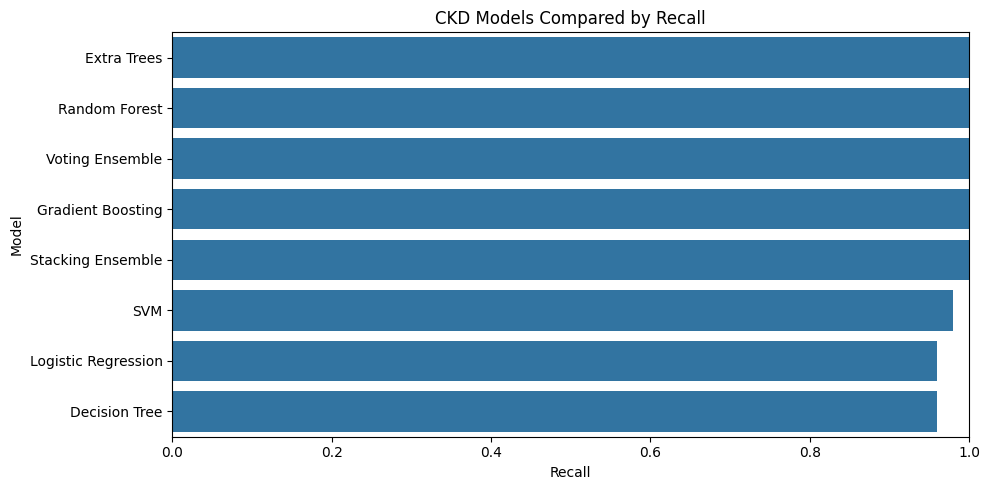


Selected model: Extra Trees

Classification Report:
              precision    recall  f1-score   support

     Not CKD       1.00      1.00      1.00        30
         CKD       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



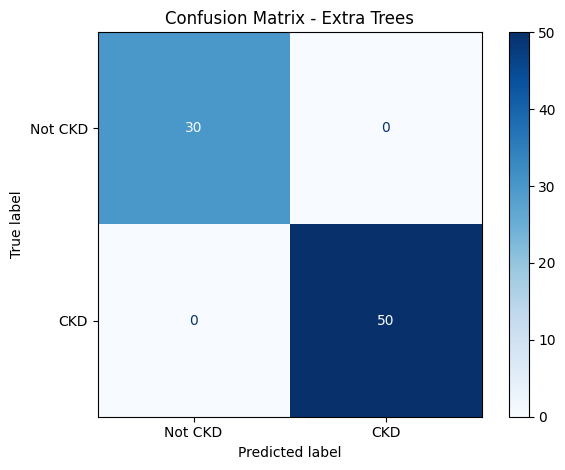

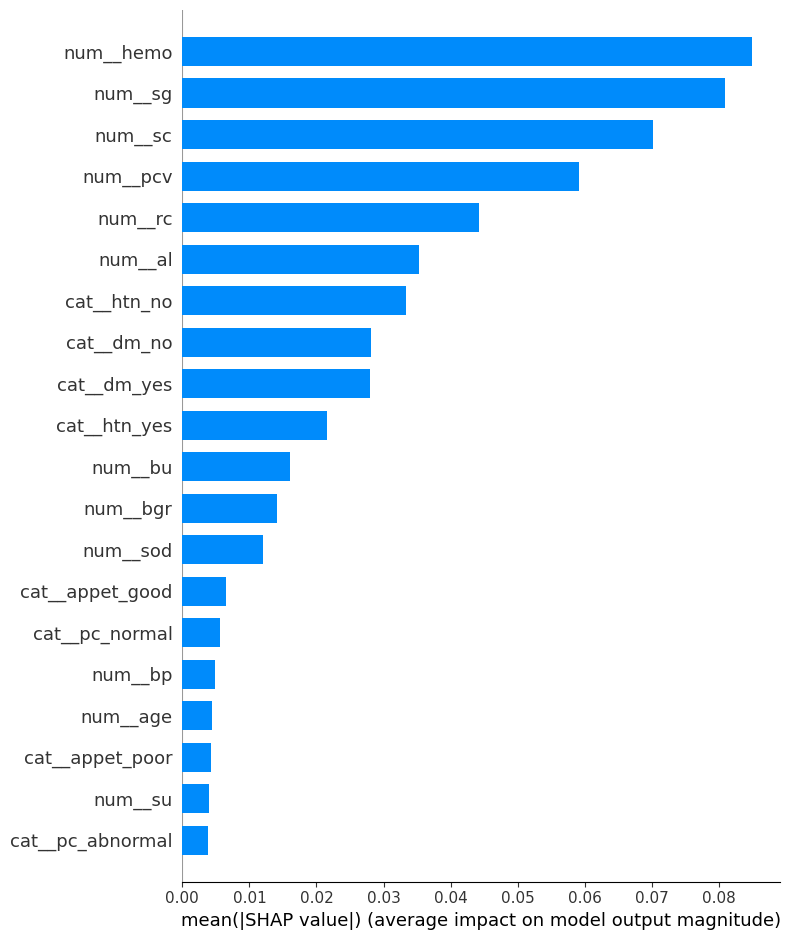

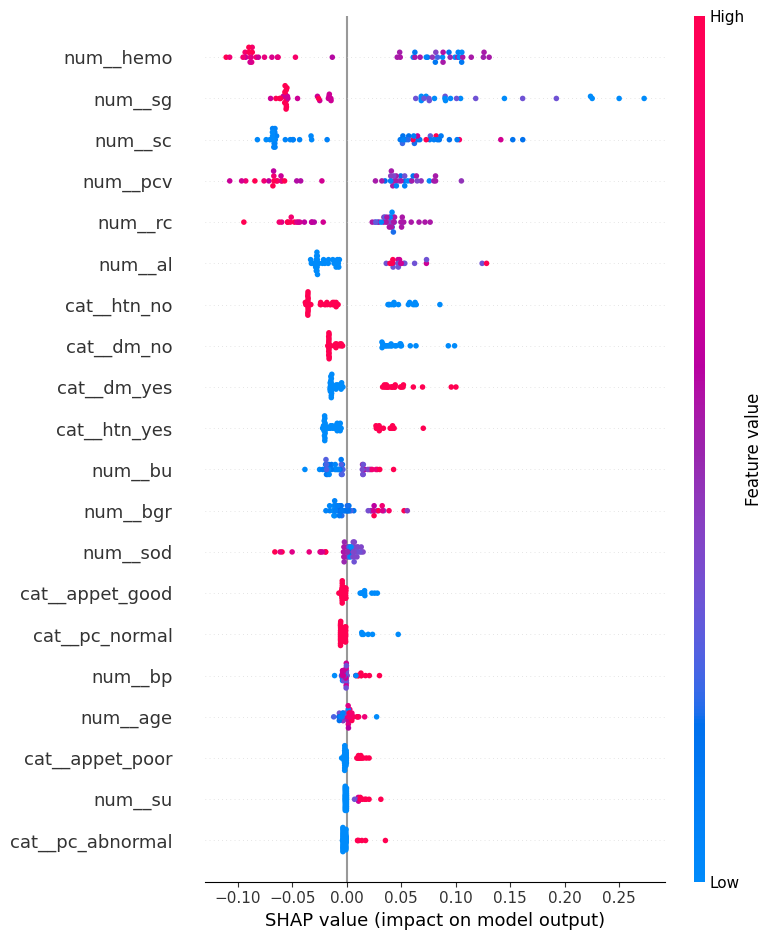


Saved files:
/content/ckd_tabular_ensemble_model.joblib
/content/ckd_random_forest_model.joblib
/content/tabular_model_results.csv

Example prediction from the held-out test set:
Model: Extra Trees
Predicted class: Not CKD
Predicted CKD probability: 0.50%
Predicted Not CKD probability: 99.50%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT COMPLETE: tabular CKD ML training finished.


In [15]:

# ================================================================
# CHRONIC KIDNEY DISEASE (CKD) PREDICTION
# COMPLETE TABULAR ML ENSEMBLE PROJECT - SINGLE COLAB CELL
# ================================================================
# Dataset: CKD tabular CSV
# Target: CKD (1) / Not CKD (0)
# Models: Logistic Regression, Decision Tree, Random Forest,
#         Extra Trees, SVM, Gradient Boosting, Voting, Stacking
# Explainability: SHAP
# Outputs: Model comparison, classification report, confusion
#           matrix, SHAP plots, saved model files
# ================================================================

!pip -q install scikit-learn pandas numpy matplotlib seaborn shap joblib

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, VotingClassifier,
    StackingClassifier
)
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# ------------------------------------------------
# 1. LOAD THE CSV DATASET
# ------------------------------------------------
# Uses a CSV already present in /content, or asks
# you to upload one if no CSV is found.
csv_files = glob.glob("/content/kidney_disease.csv")

if not csv_files:
    print("Upload your CKD dataset CSV file:")
    uploaded = files.upload()
    csv_files = [
        "/content/" + name
        for name in uploaded
        if name.lower().endswith(".csv")
    ]

if not csv_files:
    raise ValueError("No CSV found. Please upload your CKD dataset.")

print("Available CSV files:")
for i, path in enumerate(csv_files):
    print(i, os.path.basename(path))

# If there are multiple CSV files, change the index below.
# For example, use csv_files[1] for the second CSV.
DATA_PATH = csv_files[0]

df = pd.read_csv(DATA_PATH)

# Standardize column names to avoid naming inconsistencies.
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# ------------------------------------------------
# 2. CLEAN MISSING VALUES AND DATA TYPES
# ------------------------------------------------
# IMPORTANT FIX:
# Replace pandas <NA>, '?', blank strings, and common
# missing-value text with np.nan BEFORE sklearn processing.
# Convert string columns to ordinary Python strings/objects
# so pandas nullable StringDtype does not cause pd.NA errors.

missing_tokens = {
    "?": np.nan,
    "": np.nan,
    "nan": np.nan,
    "none": np.nan,
    "null": np.nan,
    "<na>": np.nan
}

for col in df.columns:
    if (
        pd.api.types.is_object_dtype(df[col])
        or isinstance(df[col].dtype, pd.StringDtype)
    ):
        s = df[col].astype("object")
        s = s.map(
            lambda v: v.strip() if isinstance(v, str) else v
        )
        s = s.map(
            lambda v: missing_tokens.get(v.lower(), v)
            if isinstance(v, str) else v
        )
        # Convert pandas NA values to ordinary np.nan.
        df[col] = s.where(pd.notna(s), np.nan)

print("\nDataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

# ------------------------------------------------
# 3. FIND AND PREPARE THE TARGET COLUMN
# ------------------------------------------------
possible_targets = [
    "classification", "class", "target", "label", "diagnosis"
]
TARGET = next((c for c in possible_targets if c in df.columns), None)

if TARGET is None:
    raise ValueError(
        "Target column not found. Check df.columns and set TARGET "
        "to the correct target column name."
    )

# Normalize labels, including trailing periods and whitespace.
target_text = (
    df[TARGET].astype("object")
    .map(lambda v: str(v).strip().lower() if pd.notna(v) else np.nan)
    .map(lambda v: v.replace(".", "").replace(" ", "") if isinstance(v, str) else v)
)

target_mapping = {
    "ckd": 1, "yes": 1, "positive": 1, "1": 1,
    "notckd": 0, "nonckd": 0, "not_ckd": 0,
    "no": 0, "negative": 0, "0": 0
}

y = target_text.map(target_mapping)
valid_rows = y.notna()

# Remove rows without a valid target.
df = df.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

# Remove target and likely identifier columns from predictors.
X = df.drop(columns=[TARGET]).copy()
id_columns = [
    c for c in X.columns
    if c in ["id", "patient_id", "record_id", "unnamed: 0"]
]
X = X.drop(columns=id_columns, errors="ignore")

# Remove duplicate feature/label rows.
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)
combined = X.copy()
combined["_target_"] = y
combined = combined.drop_duplicates().reset_index(drop=True)
y = combined.pop("_target_").astype(int)
X = combined

if y.nunique() != 2:
    raise ValueError(
        "The target must contain two classes. Check the target labels "
        "and update target_mapping if needed."
    )

print("\nTarget distribution (0=Not CKD, 1=CKD):")
print(y.value_counts().sort_index())

# ------------------------------------------------
# 4. CONVERT NUMERIC COLUMNS SAFELY
# ------------------------------------------------
# If a column is mostly numeric but stored as text,
# convert it to numbers. Non-numeric values become np.nan.
# All remaining missing values are standardized as np.nan.

for col in X.columns:
    X[col] = X[col].replace({pd.NA: np.nan})

    if (
        pd.api.types.is_object_dtype(X[col])
        or isinstance(X[col].dtype, pd.StringDtype)
    ):
        nonmissing = X[col].notna().sum()

        if nonmissing > 0:
            converted = pd.to_numeric(X[col], errors="coerce")
            ratio = converted.notna().sum() / nonmissing

            if ratio >= 0.80:
                X[col] = converted
            else:
                # Convert categorical values to regular Python strings.
                X[col] = X[col].map(
                    lambda v: str(v).strip() if pd.notna(v) else np.nan
                )

# Force pandas nullable values to standard NumPy-compatible missing values.
X = X.astype(object)
X = X.where(pd.notna(X), np.nan)
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns with no usable values.
empty_columns = [
    col for col in X.columns if X[col].notna().sum() == 0
]
if empty_columns:
    print("Dropping entirely empty columns:", empty_columns)
    X = X.drop(columns=empty_columns)

# ------------------------------------------------
# 5. TRAIN/TEST SPLIT
# ------------------------------------------------
# Stratification preserves the class ratio in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Determine numerical and categorical columns from training data.
numeric_features = [
    c for c in X_train.columns
    if pd.api.types.is_numeric_dtype(X_train[c])
]
categorical_features = [
    c for c in X_train.columns if c not in numeric_features
]

# Numerical data: median imputation + scaling.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data: most-frequent imputation + one-hot encoding.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("num", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)

# ------------------------------------------------
# 6. DEFINE THE INDIVIDUAL ML MODELS
# ------------------------------------------------
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=SEED
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=SEED, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=SEED, n_jobs=-1
    ),
    "SVM": SVC(
        probability=True, class_weight="balanced", random_state=SEED
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, random_state=SEED
    )
}

# ------------------------------------------------
# 7. DEFINE THE ENSEMBLE MODELS
# ------------------------------------------------
# Voting combines predicted probabilities from several models.
voting_model = VotingClassifier(
    estimators=[
        ("lr", clone(models["Logistic Regression"])),
        ("rf", clone(models["Random Forest"])),
        ("gb", clone(models["Gradient Boosting"]))
    ],
    voting="soft"
)

# Stacking learns how to combine base-model predictions using
# a second-level classifier. Cross-validation happens on training data.
stacking_model = StackingClassifier(
    estimators=[
        ("lr", clone(models["Logistic Regression"])),
        ("rf", clone(models["Random Forest"])),
        ("svm", clone(models["SVM"]))
    ],
    final_estimator=LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    cv=5,
    stack_method="auto",
    n_jobs=-1
)

models["Voting Ensemble"] = voting_model
models["Stacking Ensemble"] = stacking_model

# ------------------------------------------------
# 8. TRAIN AND EVALUATE ALL MODELS
# ------------------------------------------------
results = []
trained_pipelines = {}

for name, classifier in models.items():
    print(f"\nTraining: {name}")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    # Fit preprocessing and classifier using training data only.
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Calculate performance metrics for the positive class (CKD=1).
    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    results.append(scores)
    trained_pipelines[name] = pipeline

    print(
        f"Accuracy={scores['Accuracy']:.4f}, "
        f"Recall={scores['Recall']:.4f}, "
        f"F1={scores['F1 Score']:.4f}, "
        f"ROC-AUC={scores['ROC-AUC']:.4f}"
    )

results_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df.round(4))

results_df.to_csv("/content/tabular_model_results.csv", index=False)

# ------------------------------------------------
# 9. PLOT MODEL PERFORMANCE
# ------------------------------------------------
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="F1 Score", y="Model")
plt.title("CKD Models Compared by F1 Score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Recall", y="Model")
plt.title("CKD Models Compared by Recall")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 10. EVALUATE THE SELECTED MODEL
# ------------------------------------------------
# Select the highest F1-score model for this demonstration.
# For a formal study, model selection should use training
# cross-validation; the test set should ideally be evaluated once.
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_pipelines[best_model_name]
best_predictions = best_model.predict(X_test)

print("\nSelected model:", best_model_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["Not CKD", "CKD"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    labels=[0, 1],
    display_labels=["Not CKD", "CKD"],
    cmap="Blues"
)
plt.title("Confusion Matrix - " + best_model_name)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 11. SHAP EXPLAINABILITY
# ------------------------------------------------
# Explain the Random Forest model, regardless of which model
# was selected as best in the comparison.
# SHAP values explain model behavior, not medical causation.

try:
    rf_pipeline = trained_pipelines["Random Forest"]
    rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
    rf_classifier = rf_pipeline.named_steps["classifier"]

    X_explain = X_test.iloc[:min(50, len(X_test))]
    X_transformed = rf_preprocessor.transform(X_explain)
    feature_names = rf_preprocessor.get_feature_names_out()

    # Convert sparse matrices to dense arrays for SHAP.
    if hasattr(X_transformed, "toarray"):
        X_transformed = X_transformed.toarray()

    X_transformed_df = pd.DataFrame(
        X_transformed, columns=feature_names
    )

    explainer = shap.TreeExplainer(rf_classifier)
    shap_values = explainer.shap_values(X_transformed_df)

    # Handle SHAP output formats across versions.
    if isinstance(shap_values, list):
        values_for_ckd = shap_values[1]
    elif getattr(shap_values, "ndim", 0) == 3:
        values_for_ckd = shap_values[:, :, 1]
    else:
        values_for_ckd = shap_values

    shap.summary_plot(
        values_for_ckd, X_transformed_df,
        plot_type="bar", show=True
    )
    shap.summary_plot(
        values_for_ckd, X_transformed_df, show=True
    )

except Exception as e:
    print("\nSHAP explanation could not be generated:", repr(e))
    print("Model training and evaluation are complete; SHAP can be debugged separately.")

# ------------------------------------------------
# 12. SAVE MODELS AND RESULTS
# ------------------------------------------------
# Save the complete pipeline, including preprocessing, so new
# data can be passed to it using the original input columns.
model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": X_train.columns.tolist(),
    "target_mapping": {"Not CKD": 0, "CKD": 1}
}

joblib.dump(
    model_package,
    "/content/ckd_tabular_ensemble_model.joblib"
)
joblib.dump(
    trained_pipelines["Random Forest"],
    "/content/ckd_random_forest_model.joblib"
)
results_df.to_csv("/content/tabular_model_results.csv", index=False)

print("\nSaved files:")
print("/content/ckd_tabular_ensemble_model.joblib")
print("/content/ckd_random_forest_model.joblib")
print("/content/tabular_model_results.csv")

# ------------------------------------------------
# 13. EXAMPLE PREDICTION ON A HELD-OUT ROW
# ------------------------------------------------
sample = X_test.iloc[[0]]
predicted_class = best_model.predict(sample)[0]
predicted_probabilities = best_model.predict_proba(sample)[0]

print("\nExample prediction from the held-out test set:")
print("Model:", best_model_name)
print("Predicted class:", "CKD" if predicted_class == 1 else "Not CKD")
print(f"Predicted CKD probability: {predicted_probabilities[1]:.2%}")
print(f"Predicted Not CKD probability: {predicted_probabilities[0]:.2%}")

# ------------------------------------------------
# 14. DOWNLOAD THE RESULT FILES
# ------------------------------------------------
# Download the trained pipelines and model-comparison CSV.
files.download("/content/ckd_tabular_ensemble_model.joblib")
files.download("/content/ckd_random_forest_model.joblib")
files.download("/content/tabular_model_results.csv")

print("\nPROJECT COMPLETE: tabular CKD ML training finished.")


TensorFlow version: 2.21.0
Available GPU: []

Using ZIP: /content/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone.zip
ZIP size (GB): 1.628

Dataset already extracted. Reusing existing files.

Top-level extracted items:
['CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone', '_extraction_complete.txt']

Total labeled images: 12446

Class distribution:
class_name
Normal    5077
Cyst      3709
Tumor     2283
Stone     1377
Name: count, dtype: int64


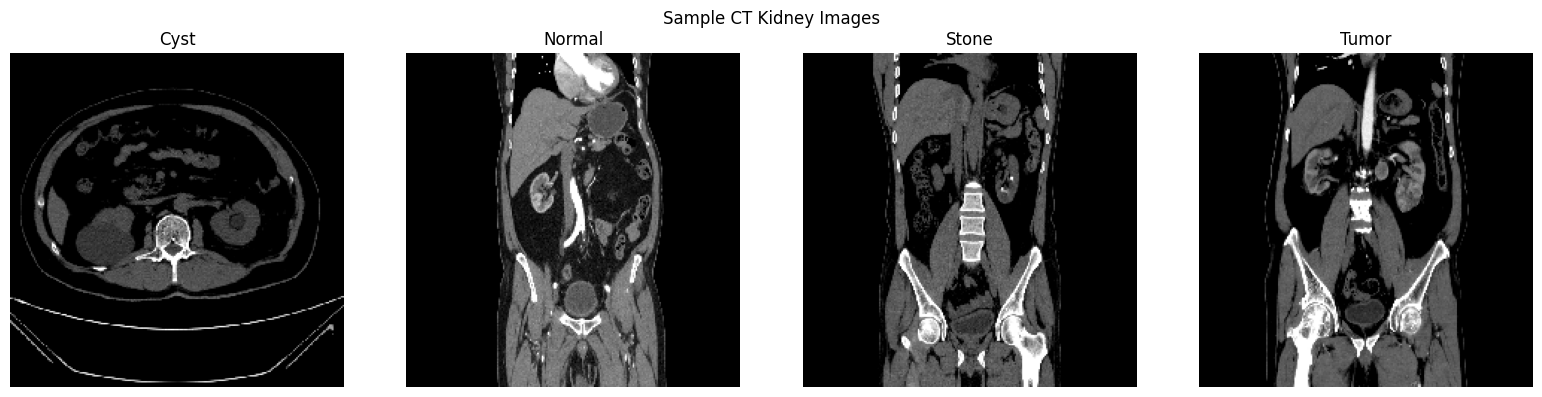


Training images: 8712
Validation images: 1867
Testing images: 1867


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Training classification head...
Epoch 1/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5912 - loss: 1.0181
Epoch 1: val_loss improved from None to 0.79882, saving model to /content/best_kidney_ct_model.keras

Epoch 1: finished saving model to /content/best_kidney_ct_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 531s 2s/step - accuracy: 0.6908 - loss: 0.7836 - val_accuracy: 0.6802 - val_loss: 0.7988 - learning_rate: 0.0010
Epoch 2/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7968 - loss: 0.5357
Epoch 2: val_loss improved from 0.79882 to 0.67714, saving model to /content/best_kidney_ct_model.keras

Epoch 2: finished saving model to /content/best_kidney_ct_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 551s 2s/step - accuracy: 0.8095 - loss: 0.5037 - val_accuracy: 0.7349 - val_loss: 0.6771 - learning_rate: 0.0010
Epoch 3/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8313 - loss: 0.4472
Epoch 3: val_loss improved from 0.67714 to 0.45216, saving model to /content/best

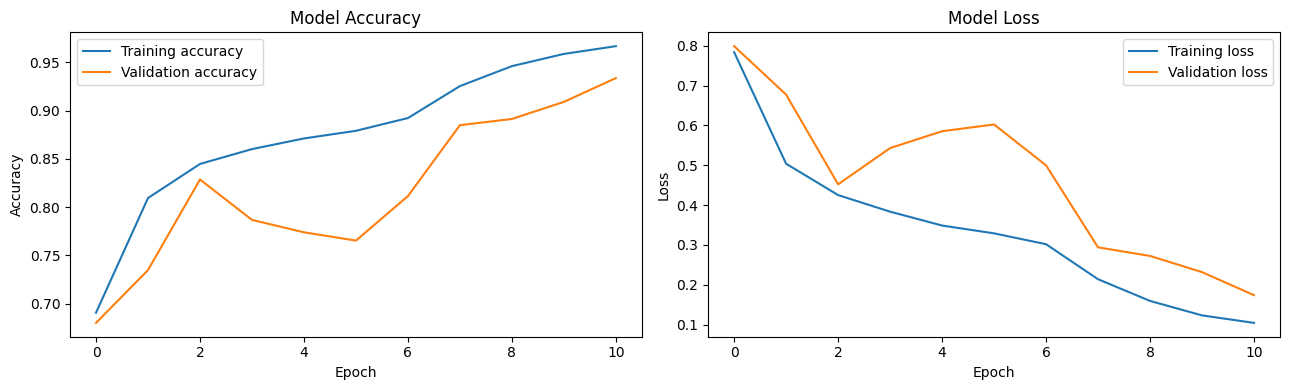

59/59 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.9363 - loss: 0.1590

========== TEST RESULTS ==========
Test loss: 0.1590
Test accuracy: 0.9363
59/59 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step

Test accuracy from predictions: 0.9363

Classification Report:
              precision    recall  f1-score   support

        Cyst       0.86      1.00      0.92       557
      Normal       0.98      0.97      0.98       761
       Stone       0.92      0.85      0.88       207
       Tumor       0.99      0.82      0.90       342

    accuracy                           0.94      1867
   macro avg       0.94      0.91      0.92      1867
weighted avg       0.94      0.94      0.94      1867



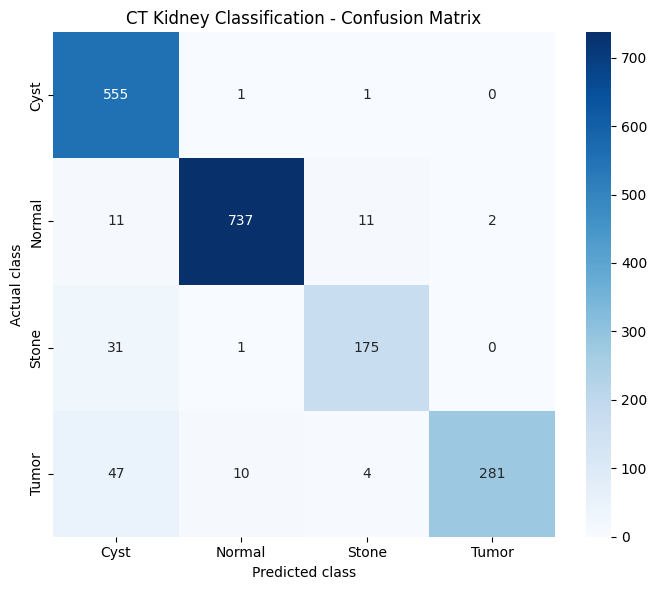

Saved test predictions to:
/content/kidney_ct_test_predictions.csv


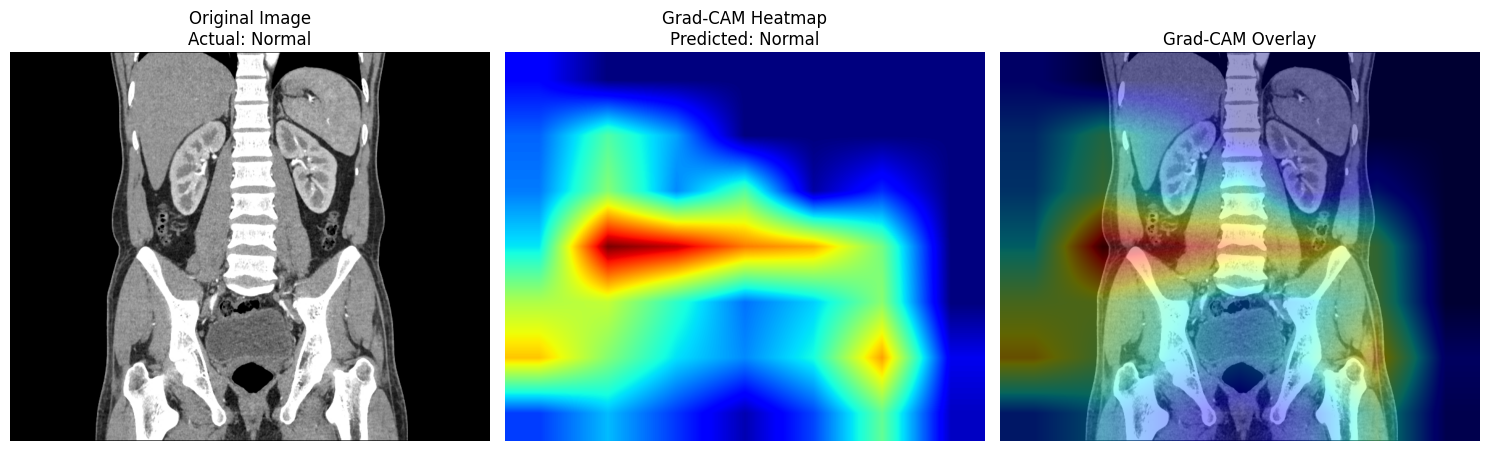

Actual class: Normal
Predicted class: Normal
Confidence: 0.9234

========== FILES SAVED ==========
Best checkpoint: /content/best_kidney_ct_model.keras
Final model: /content/kidney_ct_mobilenetv2_model.keras
Class names: /content/kidney_ct_class_names.txt
Test predictions: /content/kidney_ct_test_predictions.csv
Train split: /content/kidney_ct_train_split.csv
Validation split: /content/kidney_ct_validation_split.csv
Test split: /content/kidney_ct_test_split.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Training and evaluation completed.


In [20]:

# ============================================================
# CT KIDNEY IMAGE CLASSIFICATION USING MOBILENETV2
# Classes: Normal, Cyst, Tumor, Stone
# Explainability: Grad-CAM
# Google Colab - Run this entire cell
# ============================================================

import os
import zipfile
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import seaborn as sns

warnings.filterwarnings("ignore")

# -------------------- 1. CONFIGURATION --------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

ZIP_PATH = "/content/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone.zip"

# IMPORTANT: This must be a folder, not kidneyData.csv
EXTRACT_DIR = "/content/kidney_ct_dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
HEAD_EPOCHS = 10
FINE_TUNE_EPOCHS = 5

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

# -------------------- 2. FIND THE ZIP FILE --------------------

if not os.path.isfile(ZIP_PATH):
    possible_zips = [
        str(p) for p in Path("/content").glob("*.zip")
    ]

    if possible_zips:
        print("\nZIP files found:")
        for i, path in enumerate(possible_zips):
            print(i, path)

        # Select the expected dataset ZIP if available
        matching = [
            p for p in possible_zips
            if "kidney" in os.path.basename(p).lower()
            and "ct" in os.path.basename(p).lower()
        ]

        if matching:
            ZIP_PATH = matching[0]
        elif len(possible_zips) == 1:
            ZIP_PATH = possible_zips[0]
        else:
            raise FileNotFoundError(
                "Multiple ZIP files found. Set ZIP_PATH to the "
                "correct CT kidney dataset ZIP file."
            )
    else:
        from google.colab import files
        print("Upload the CT kidney dataset ZIP file.")
        uploaded = files.upload()

        zip_names = [
            name for name in uploaded if name.lower().endswith(".zip")
        ]
        if not zip_names:
            raise FileNotFoundError("No ZIP file was uploaded.")

        ZIP_PATH = "/content/" + zip_names[0]

print("\nUsing ZIP:", ZIP_PATH)
print("ZIP size (GB):", round(os.path.getsize(ZIP_PATH) / 1e9, 3))

# -------------------- 3. EXTRACT DATASET --------------------

os.makedirs(EXTRACT_DIR, exist_ok=True)

marker_file = os.path.join(EXTRACT_DIR, "_extraction_complete.txt")

# Reuse the extracted dataset only when its completion marker exists.
if not os.path.exists(marker_file):
    print("\nExtracting dataset. This may take several minutes...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    with open(marker_file, "w") as f:
        f.write("Extraction completed")

    print("Extraction completed successfully.")
else:
    print("\nDataset already extracted. Reusing existing files.")

print("\nTop-level extracted items:")
print(os.listdir(EXTRACT_DIR)[:15])

# -------------------- 4. FIND IMAGE FILES AND LABELS --------------------

CLASS_NAMES = ["Cyst", "Normal", "Stone", "Tumor"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_class_from_path(image_path):
    """
    Detect class from a directory name in the image path.
    Handles common variations such as Tumour and Calculi.
    """
    parts = [part.lower().replace("_", " ").replace("-", " ")
             for part in Path(image_path).parts]

    for part in reversed(parts):
        words = part.split()

        # Prefer explicit class-folder names
        if "normal" in words:
            return "Normal"
        if "cyst" in words:
            return "Cyst"
        if "stone" in words or "calculus" in words or "calculi" in words:
            return "Stone"
        if "tumor" in words or "tumour" in words:
            return "Tumor"

    return None

image_paths = []
image_labels = []

for path in Path(EXTRACT_DIR).rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        label = get_class_from_path(str(path))
        if label is not None:
            image_paths.append(str(path))
            image_labels.append(label)

if len(image_paths) == 0:
    raise ValueError(
        "No labeled images were found. Check the extracted folder structure. "
        "Expected folders containing Normal, Cyst, Stone, or Tumor images."
    )

df = pd.DataFrame({
    "image_path": image_paths,
    "class_name": image_labels
})

print("\nTotal labeled images:", len(df))
print("\nClass distribution:")
print(df["class_name"].value_counts())

missing_classes = set(CLASS_NAMES) - set(df["class_name"].unique())
if missing_classes:
    raise ValueError(
        f"These classes were not found: {missing_classes}. "
        "Check the ZIP folder structure and class-folder names."
    )

# -------------------- 5. DISPLAY SAMPLE IMAGES --------------------

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, class_name in zip(axes, CLASS_NAMES):
    sample = df[df["class_name"] == class_name].iloc[0]
    image = tf.keras.utils.load_img(
        sample["image_path"], target_size=IMG_SIZE
    )
    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Sample CT Kidney Images")
plt.tight_layout()
plt.show()

# -------------------- 6. TRAIN / VALIDATION / TEST SPLIT --------------------
# Image-level split. If multiple images belong to the same patient,
# split by patient ID instead to prevent data leakage.

train_df, temporary_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["class_name"]
)

val_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_df["class_name"]
)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# Save the split manifests for reproducibility
train_df.to_csv("/content/kidney_ct_train_split.csv", index=False)
val_df.to_csv("/content/kidney_ct_validation_split.csv", index=False)
test_df.to_csv("/content/kidney_ct_test_split.csv", index=False)

# -------------------- 7. CREATE TENSORFLOW DATASETS --------------------

AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(dataframe, training=False):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["class_name"].map(CLASS_TO_ID).to_numpy(
        dtype=np.int32
    )

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 2000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)

    # Cache validation/test data in memory when practical.
    # Avoid caching training data to limit RAM use.
    if not training:
        dataset = dataset.cache()

    return dataset.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# -------------------- 8. DATA AUGMENTATION --------------------

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name="data_augmentation")

# -------------------- 9. BUILD MOBILENETV2 MODEL --------------------

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

x = data_augmentation(inputs)

# MobileNetV2 expects input pixels scaled to [-1, 1].
x = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5, offset=-1
)(x)

x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)

outputs = tf.keras.layers.Dense(
    len(CLASS_NAMES), activation="softmax", name="predictions"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# -------------------- 10. TRAIN CLASSIFICATION HEAD --------------------

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_kidney_ct_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("\nTraining classification head...")

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks
)

# -------------------- 11. FINE-TUNE LAST MOBILENETV2 LAYERS --------------------

print("\nFine-tuning MobileNetV2...")

base_model.trainable = True

# Freeze earlier layers and fine-tune only the last 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks
)

# -------------------- 12. PLOT TRAINING CURVES --------------------

def combine_history(histories, metric):
    values = []
    for hist in histories:
        values.extend(hist.history.get(metric, []))
    return values

train_acc = combine_history([history_head, history_fine], "accuracy")
val_acc = combine_history([history_head, history_fine], "val_accuracy")
train_loss = combine_history([history_head, history_fine], "loss")
val_loss = combine_history([history_head, history_fine], "val_loss")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(train_acc, label="Training accuracy")
axes[0].plot(val_acc, label="Validation accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(train_loss, label="Training loss")
axes[1].plot(val_loss, label="Validation loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

# -------------------- 13. LOAD BEST CHECKPOINT --------------------

model = tf.keras.models.load_model(
    "/content/best_kidney_ct_model.keras"
)

# -------------------- 14. TEST EVALUATION --------------------

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\n========== TEST RESULTS ==========")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

y_true = test_df["class_name"].map(CLASS_TO_ID).to_numpy()

print("\nTest accuracy from predictions:",
      round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

# -------------------- 15. CONFUSION MATRIX --------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("CT Kidney Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

# -------------------- 16. SAVE TEST PREDICTIONS --------------------

prediction_df = test_df.copy()
prediction_df["actual_class"] = [
    CLASS_NAMES[i] for i in y_true
]
prediction_df["predicted_class"] = [
    CLASS_NAMES[i] for i in y_pred
]
prediction_df["confidence"] = np.max(probabilities, axis=1)

for i, class_name in enumerate(CLASS_NAMES):
    prediction_df[f"prob_{class_name.lower()}"] = probabilities[:, i]

prediction_df.to_csv(
    "/content/kidney_ct_test_predictions.csv", index=False
)

print("Saved test predictions to:")
print("/content/kidney_ct_test_predictions.csv")

# -------------------- 17. GRAD-CAM EXPLAINABILITY --------------------
# Build a model that exposes MobileNetV2's final convolutional
# features and final feature vector. Reuse the trained layers so
# gradients flow from the class score back to the convolutional map.

last_conv_layer = base_model.get_layer("out_relu")

grad_base_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[last_conv_layer.output, base_model.output]
)

rescaling_layer = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Rescaling)
)
pooling_layer = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D)
)
dropout_layer = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dropout)
)
classifier_layer = model.get_layer("predictions")

def make_gradcam_heatmap(image_path, class_index=None):
    # Load original-sized image for display
    original = tf.keras.utils.load_img(image_path)
    display_array = tf.keras.utils.img_to_array(original)

    # Prepare image for model
    resized = tf.keras.utils.load_img(
        image_path, target_size=IMG_SIZE
    )
    image_array = tf.keras.utils.img_to_array(resized)
    image_batch = tf.expand_dims(image_array, axis=0)

    with tf.GradientTape() as tape:
        scaled = rescaling_layer(image_batch)

        conv_outputs, base_features = grad_base_model(
            scaled, training=False
        )

        pooled_features = pooling_layer(base_features)
        dropped_features = dropout_layer(
            pooled_features, training=False
        )
        predictions = classifier_layer(dropped_features)

        if class_index is None:
            class_index = tf.argmax(
                predictions[0]
            ).numpy().item()

        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)

    if gradients is None:
        raise RuntimeError(
            "Grad-CAM gradients could not be calculated."
        )

    # Average gradients over spatial dimensions
    weights = tf.reduce_mean(gradients, axis=(1, 2))

    conv_outputs = conv_outputs[0]
    weights = weights[0]

    heatmap = tf.reduce_sum(
        conv_outputs * weights[tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    maximum = tf.reduce_max(heatmap)

    heatmap = heatmap / (maximum + tf.keras.backend.epsilon())
    heatmap = heatmap.numpy()

    return display_array.astype("uint8"), heatmap, predictions.numpy()[0]

# Select one test image and visualize its explanation
sample_path = test_df.iloc[0]["image_path"]

original_image, heatmap, sample_probs = make_gradcam_heatmap(
    sample_path
)

predicted_index = int(np.argmax(sample_probs))
predicted_class = CLASS_NAMES[predicted_index]
actual_class = test_df.iloc[0]["class_name"]

# Resize heatmap to original image dimensions
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (original_image.shape[0], original_image.shape[1])
).numpy().squeeze()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nActual: {actual_class}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title(f"Grad-CAM Heatmap\nPredicted: {predicted_class}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.40)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print("Confidence:", round(float(sample_probs[predicted_index]), 4))

# -------------------- 18. PREDICT A NEW IMAGE --------------------

def predict_kidney_image(image_path, show_gradcam=True):
    """
    Predict Normal, Cyst, Stone, or Tumor for one CT image.
    Optionally display Grad-CAM explanation.
    """
    if not os.path.isfile(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    resized = tf.keras.utils.load_img(
        image_path, target_size=IMG_SIZE
    )
    array = tf.keras.utils.img_to_array(resized)
    batch = tf.expand_dims(array, axis=0)

    probs = model.predict(batch, verbose=0)[0]
    predicted_index = int(np.argmax(probs))

    print("\nPredicted class:", CLASS_NAMES[predicted_index])
    print("Confidence:", f"{probs[predicted_index]:.4f}")
    print("\nClass probabilities:")

    for class_name, probability in zip(CLASS_NAMES, probs):
        print(f"{class_name}: {probability:.4f}")

    if show_gradcam:
        original, cam, _ = make_gradcam_heatmap(
            image_path, class_index=predicted_index
        )

        cam_resized = tf.image.resize(
            cam[..., np.newaxis],
            (original.shape[0], original.shape[1])
        ).numpy().squeeze()

        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(original)
        plt.title("Input CT Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(original)
        plt.imshow(cam_resized, cmap="jet", alpha=0.40)
        plt.title(f"Grad-CAM: {CLASS_NAMES[predicted_index]}")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

    return {
        "predicted_class": CLASS_NAMES[predicted_index],
        "confidence": float(probs[predicted_index]),
        "probabilities": {
            name: float(prob)
            for name, prob in zip(CLASS_NAMES, probs)
        }
    }

# Example:
# predict_kidney_image("/content/my_kidney_ct_image.jpg")

# -------------------- 19. SAVE FINAL MODEL AND CLASS NAMES --------------------

FINAL_MODEL_PATH = "/content/kidney_ct_mobilenetv2_model.keras"
CLASS_NAMES_PATH = "/content/kidney_ct_class_names.txt"

model.save(FINAL_MODEL_PATH)

with open(CLASS_NAMES_PATH, "w") as f:
    f.write("\n".join(CLASS_NAMES))

print("\n========== FILES SAVED ==========")
print("Best checkpoint: /content/best_kidney_ct_model.keras")
print("Final model:", FINAL_MODEL_PATH)
print("Class names:", CLASS_NAMES_PATH)
print("Test predictions: /content/kidney_ct_test_predictions.csv")
print("Train split: /content/kidney_ct_train_split.csv")
print("Validation split: /content/kidney_ct_validation_split.csv")
print("Test split: /content/kidney_ct_test_split.csv")

# Download the model and supporting files to your computer
from google.colab import files

files.download(FINAL_MODEL_PATH)
files.download(CLASS_NAMES_PATH)
files.download("/content/kidney_ct_test_predictions.csv")

print("\nTraining and evaluation completed.")
